<a href="https://colab.research.google.com/github/joikonjojo-creator/pattern-recognition-practice/blob/main/notebooks/PR03_Chirva_Daniil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 3

## Перша модель і базове оцінювання якості

**Дисципліна:** Розпізнавання образів і машинне навчання

**Студент:** Чирва Данііл

**Група:** ІН-42/1

**Дата виконання:** 18.10.2026

### Мета роботи

Побудувати першу завершену модель машинного навчання,
отримати прогнози та навчитися оцінювати їхню якість
за допомогою основних метрик класифікації.

## 1. Підключення бібліотек

In [36]:
from pathlib import Path

import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

from IPython.display import display

In [37]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "iris_cleaned.csv"
)

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODEL_PATH = MODELS_DIR / "iris_decision_tree.joblib"
METRICS_PATH = REPORTS_DIR / "model_metrics.csv"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Файл даних:", DATA_PATH)
print("Файл моделі:", MODEL_PATH)

Файл даних: /content/drive/MyDrive/pattern-recognition-practice/data/processed/iris_cleaned.csv
Файл моделі: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib


## 2. Завантаження підготовленого набору даних

In [39]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Файл iris_cleaned.csv не знайдено. "
        "Перевірте виконання практичної роботи 2."
    )

data = pd.read_csv(DATA_PATH)

display(data.head())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,5.8,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,5.1,3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


In [40]:
print("Розмір таблиці:", data.shape)
print("\nТипи даних:")
print(data.dtypes)

print(
    "\nКількість пропусків:",
    data.isna().sum().sum()
)

Розмір таблиці: (148, 6)

Типи даних:
sepal_length_cm       float64
sepal_width_cm        float64
petal_length_cm       float64
petal_width_cm        float64
species                object
measurement_device     object
dtype: object

Кількість пропусків: 0


1. Очищений набір містить 148 об'єктів.
2. Доступно 5 ознак: 4 числові (розміри чашолистка й пелюстки) і 1 категоріальна (`measurement_device`).
3. Пропущених значень не залишилося.
4. Цільова змінна: `species`.

In [41]:
X = data.drop(columns=["species"])
y = data["species"]

categorical_columns = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print(
    "Категоріальні ознаки:",
    categorical_columns
)

Категоріальні ознаки: ['measurement_device']


In [42]:
X = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)

display(X.head())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,0,0,1
1,5.8,3.0,1.4,0.2,0,1,0
2,4.7,3.2,1.3,0.2,0,0,1
3,5.1,3.1,1.5,0.2,0,1,0
4,5.0,3.6,1.4,0.2,1,0,0


In [43]:
print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

Розмір X: (148, 7)
Розмір y: (148,)


In [44]:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

In [45]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (118, 7)
X_test: (30, 7)
y_train: (118,)
y_test: (30,)


In [46]:
split_distribution = pd.DataFrame(
    {
        "train_percent": (
            y_train
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        ),
        "test_percent": (
            y_test
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)

display(split_distribution)

,train_percent,test_percent
species,,
setosa,33.90,33.33
versicolor,33.05,33.33
virginica,33.05,33.33


1. **Чому тестова вибірка не використовується для навчання?**
Тестова вибірка імітує нові дані, яких модель ще не бачила. Якщо модель навчатиметься і на ній, вона просто запам'ятає ці об'єкти. Тоді результат на тесті буде кращим, ніж реальна якість роботи з новими квітками.

2. **Для чого встановлено `random_state=42`?**
Перед поділом `train_test_split` випадково перемішує рядки, а `random_state` фіксує початкове значення генератора випадкових чисел. Тому при кожному запуску в тест потрапляють ті самі 30 об'єктів, і результати можна відтворити та порівняти між собою. Саме число 42 нічого не означає, можна взяти будь-яке інше.

3. **Для чого використовується `stratify=y`?**
Цей параметр розбиває дані так, щоб співвідношення видів у train і test було таким самим, як у всьому наборі. У результаті в тесті по 10 об'єктів кожного виду, а в навчальній вибірці 40 `setosa` і по 39 `versicolor` та `virginica`. Без нього випадкове розбиття могло б дати тест, у якому одного з видів майже немає.

4. **Чи близькі частки класів у train і test?**
Так, частки практично однакові: `setosa` займає 33,90 % у train і 33,33 % у test, `versicolor` і `virginica` по 33,05 % і 33,33 %. Найбільше розходження становить приблизно 0,57 відсоткового пункта.

## 3. Базова модель DummyClassifier

DummyClassifier використовується як найпростіший орієнтир.
Він не аналізує ознаки та прогнозує найпоширеніший клас.

In [47]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

In [48]:
dummy_model.fit(
    X_train,
    y_train
)

DummyClassifier(strategy='most_frequent')

In [49]:
dummy_train_predictions = dummy_model.predict(
    X_train
)

dummy_test_predictions = dummy_model.predict(
    X_test
)

In [50]:
dummy_preview = pd.DataFrame(
    {
        "actual": y_test.iloc[:10].values,
        "predicted": dummy_test_predictions[:10]
    }
)

display(dummy_preview)

,actual,predicted
0,versicolor,setosa
1,versicolor,setosa
2,virginica,setosa
3,setosa,setosa
4,virginica,setosa
5,versicolor,setosa
6,versicolor,setosa
7,setosa,setosa
8,virginica,setosa
9,virginica,setosa


### Відповіді до базової моделі

DummyClassifier для кожного об'єкта видає `setosa`, бо в навчальній вибірці цього виду найбільше: 40 об'єктів проти 39 в інших. Вважати таку модель достатньою не можна, оскільки значення ознак вона взагалі не використовує, а лише повторює найчастіший клас. Серед перших 10 прогнозів правильними виявилися тільки 2, обидва для справжніх `setosa`, а жодного `versicolor` чи `virginica` модель не визначила.

## 4. Дерево рішень

Будується дерево рішень з обмеженою максимальною глибиною.

In [51]:
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

In [52]:
tree_model.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [53]:
tree_train_predictions = tree_model.predict(
    X_train
)

tree_test_predictions = tree_model.predict(
    X_test
)

In [54]:
prediction_preview = pd.DataFrame(
    {
        "actual": y_test.iloc[:15].values,
        "predicted": tree_test_predictions[:15]
    }
)

prediction_preview["correct"] = (
    prediction_preview["actual"]
    == prediction_preview["predicted"]
)

display(prediction_preview)

,actual,predicted,correct
0,versicolor,versicolor,True
1,versicolor,versicolor,True
2,virginica,virginica,True
3,setosa,setosa,True
4,virginica,virginica,True
5,versicolor,versicolor,True
6,versicolor,versicolor,True
7,setosa,setosa,True
8,virginica,virginica,True
9,virginica,virginica,True


### Відповідь до дерева рішень

Усі 15 перших прогнозів дерева правильні: у стовпці `correct` немає жодного `False`. Проте це лише половина тестової вибірки (15 з 30 об'єктів), тому загальну якість моделі треба оцінювати за метриками на всьому тесті.

In [55]:
def calculate_metrics(
    model_name,
    dataset_name,
    y_true,
    y_pred
):
    """
    Обчислює основні метрики багатокласової класифікації.
    """
    return {
        "model": model_name,
        "dataset": dataset_name,
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

In [56]:
metrics_rows = [
    calculate_metrics(
        "DummyClassifier",
        "train",
        y_train,
        dummy_train_predictions
    ),
    calculate_metrics(
        "DummyClassifier",
        "test",
        y_test,
        dummy_test_predictions
    ),
    calculate_metrics(
        "DecisionTree",
        "train",
        y_train,
        tree_train_predictions
    ),
    calculate_metrics(
        "DecisionTree",
        "test",
        y_test,
        tree_test_predictions
    )
]

metrics_df = pd.DataFrame(metrics_rows)

display(
    metrics_df.round(3)
)

,model,dataset,accuracy,precision_macro,recall_macro,f1_macro
0,DummyClassifier,train,0.339,0.113,0.333,0.169
1,DummyClassifier,test,0.333,0.111,0.333,0.167
2,DecisionTree,train,0.983,0.984,0.983,0.983
3,DecisionTree,test,0.933,0.936,0.933,0.933


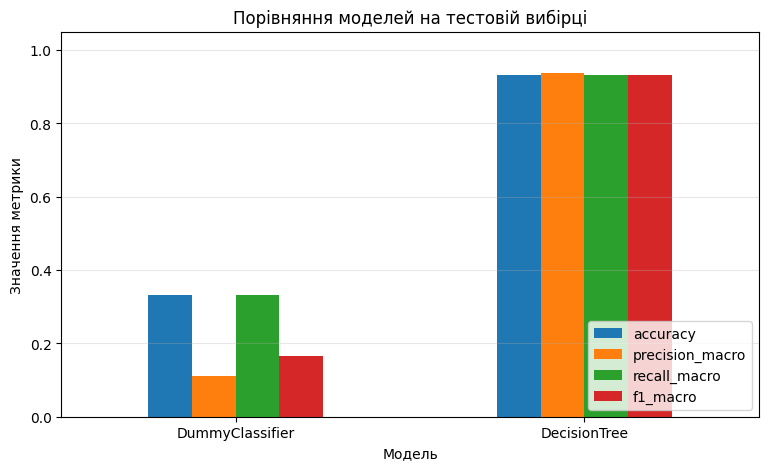

In [57]:
test_metrics = (
    metrics_df[
        metrics_df["dataset"] == "test"
    ]
    .set_index("model")
)

test_metrics[
    [
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Порівняння моделей на тестовій вибірці"
)

plt.xlabel("Модель")
plt.ylabel("Значення метрики")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(
    loc="lower right"
)
plt.show()

### Відповіді до порівняння моделей

1. Вища accuracy у дерева рішень: 0.933, тоді як у DummyClassifier 0.333.

2. За F1-мірою дерево теж краще: 0.933 проти 0.167.

3. Дерево виграє за кожною метрикою. Accuracy і recall_macro у нього більші на 0.600, тобто приблизно у 2.8 раза. F1-міра більша приблизно на 0.77, тобто приблизно у 5.6 раза. Precision_macro більша приблизно на 0.83, тобто приблизно у 8.4 раза.

4. Accuracy показує лише загальну частку правильних відповідей, але не показує, з якими класами модель не справляється. У DummyClassifier accuracy 0.333, хоча precision_macro всього 0.111, а F1-міра 0.167: модель прогнозує лише один вид із трьох, а два інші не називає жодного разу. Precision, recall і F1-міра обчислюються окремо для кожного класу, тому в них такі проблеми видно. Ще ризикованіше дивитися лише на accuracy, коли класи сильно відрізняються за розміром. Тоді модель, яка завжди називає найбільший клас, отримає високу accuracy, хоча нічого корисного не робить.

In [58]:
train_test_comparison = metrics_df.pivot(
    index="model",
    columns="dataset",
    values=[
        "accuracy",
        "f1_macro"
    ]
)

display(
    train_test_comparison.round(3)
)

accuracy        f1_macro       
dataset             test  train     test  train
model                                          
DecisionTree       0.933  0.983    0.933  0.983
DummyClassifier    0.333  0.339    0.167  0.169

In [59]:
tree_train_accuracy = accuracy_score(
    y_train,
    tree_train_predictions
)

tree_test_accuracy = accuracy_score(
    y_test,
    tree_test_predictions
)

accuracy_gap = (
    tree_train_accuracy
    - tree_test_accuracy
)

print(
    "Accuracy на train:",
    round(tree_train_accuracy, 3)
)

print(
    "Accuracy на test:",
    round(tree_test_accuracy, 3)
)

print(
    "Різниця:",
    round(accuracy_gap, 3)
)

Accuracy на train: 0.983
Accuracy на test: 0.933
Різниця: 0.05


### Відповіді до порівняння train і test

1. **Чи недонавчений DummyClassifier?**
Так, DummyClassifier недонавчений. Він погано працює на обох вибірках: accuracy 0.339 на train і 0.333 на test, F1-міра 0.169 і 0.167. Результати майже не відрізняються, але обидва незадовільні, адже модель не враховує ознаки і щоразу видає `setosa`.

2. **Чи є ознаки перенавчання дерева?**
Суттєвих ознак перенавчання немає. Accuracy і F1-міра дерева на train дорівнюють 0.983, на test 0.933, тобто розрив лише 0.05. На нових об'єктах модель працює лише трохи гірше, ніж на навчальних, отже вона не просто запам'ятала train. До того ж у тесті всього 30 об'єктів, тому кожна помилка знижує accuracy приблизно на 0.033.

3. **Чи має дерево прийнятну узагальнювальну здатність?**
Так. На тестовій вибірці accuracy і F1-міра становлять 0.933, тобто модель добре класифікує об'єкти, яких не бачила під час навчання. Це набагато вище, ніж у DummyClassifier (0.333 і 0.167), а розрив між train і test невеликий, 0.05. Отже, виконуються всі три ознаки хорошої узагальнювальної здатності.

## 5. Матриця помилок

Матриця помилок показує, які класи модель визначає правильно,
а які плутає між собою.

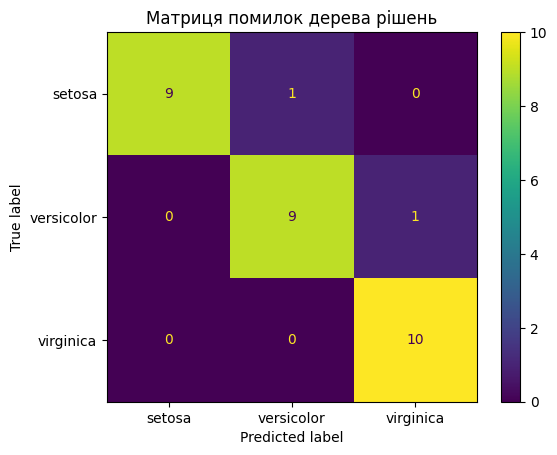

In [60]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_test_predictions
)

plt.title(
    "Матриця помилок дерева рішень"
)

plt.show()

### Відповіді до матриці помилок

1. Правильно класифіковано 28 із 30 об'єктів: на головній діагоналі 9 `setosa`, 9 `versicolor` і 10 `virginica`.

2. `virginica` розпізнається без жодної помилки, усі 10 об'єктів визначено правильно. `setosa` і `versicolor` розпізнаються майже без помилок, по 9 із 10.

3. Помилок лише дві, і кожна стосується іншої пари: один об'єкт `setosa` модель віднесла до `versicolor`, а один `versicolor` до `virginica`. Тобто жодна пара не плутається частіше за іншу, але `versicolor` присутній в обох помилках.

4. Плутанина між `versicolor` і `virginica` очікувана, бо на діаграмах попередньої роботи ці види частково перекривалися. Помилка з `setosa` діаграмам не відповідає, адже там цей вид був чітко відділений від інших. Її причину розглянуто в аналізі помилкових прогнозів нижче.

In [61]:
test_results = X_test.copy()

test_results["actual"] = y_test.values
test_results["predicted"] = tree_test_predictions

test_results["correct"] = (
    test_results["actual"]
    == test_results["predicted"]
)

In [62]:
mistakes = test_results[
    ~test_results["correct"]
]

display(mistakes)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c,actual,predicted,correct
10,5.4,3.7,4.3,0.2,1,0,0,setosa,versicolor,False
77,6.7,3.0,5.0,1.7,0,1,0,versicolor,virginica,False


In [63]:
print(
    "Кількість помилкових прогнозів:",
    len(mistakes)
)

Кількість помилкових прогнозів: 2


### Аналіз помилкових прогнозів

Із 30 тестових об'єктів модель помилилася на двох.

**Помилка 1.** Справжній вид `setosa`, прогноз `versicolor`. Ознаки: довжина чашолистка 5.4, ширина чашолистка 3.7, довжина пелюстки 4.3, ширина пелюстки 0.2. У наших даних довжина пелюстки `setosa` зазвичай 1.3–1.5, а 4.3 типове значення для `versicolor`. Це значення збігається з медіаною, якою в практичній роботі 2 заповнювалися пропущені й аномальні значення довжини пелюстки. Тому найімовірніше, це не справжній вимір квітки, а результат заповнення медіаною, порахованою по всій колонці без урахування виду. Решта ознак цього об'єкта відповідає `setosa`.

**Помилка 2.** Справжній вид `versicolor`, прогноз `virginica`. Ознаки: довжина чашолистка 6.7, ширина чашолистка 3.0, довжина пелюстки 5.0, ширина пелюстки 1.7. Для `versicolor` така пелюстка велика, а для `virginica`, навпаки, невелика, тому об'єкт опинився в області, де ці два види перекриваються.

Тестова вибірка складається лише з 30 об'єктів, і кожна помилка знижує accuracy приблизно на 0.033. Через це результат помітно залежить від того, які саме об'єкти випадково потрапили в тест.

## 6. Збереження навченої моделі

Модель зберігається разом із назвами ознак, щоб її можна було
правильно використати в наступних роботах.

In [64]:
model_bundle = {
    "model": tree_model,
    "feature_columns": X.columns.tolist(),
    "target_classes": sorted(
        y.unique().tolist()
    )
}

In [65]:
joblib.dump(
    model_bundle,
    MODEL_PATH
)

print(
    "Модель збережено:",
    MODEL_PATH
)

Модель збережено: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib


In [66]:
loaded_bundle = joblib.load(
    MODEL_PATH
)

loaded_model = loaded_bundle["model"]

print(
    "Ознаки моделі:",
    loaded_bundle["feature_columns"]
)

print(
    "Класи:",
    loaded_bundle["target_classes"]
)

Ознаки моделі: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'measurement_device_device_a', 'measurement_device_device_b', 'measurement_device_device_c']
Класи: ['setosa', 'versicolor', 'virginica']


In [67]:
one_object = X_test.iloc[[0]]

loaded_prediction = loaded_model.predict(
    one_object
)

print(
    "Справжній клас:",
    y_test.iloc[0]
)

print(
    "Прогноз моделі:",
    loaded_prediction[0]
)

Справжній клас: versicolor
Прогноз моделі: versicolor


In [68]:
metrics_df.to_csv(
    METRICS_PATH,
    index=False
)

print(
    "Таблицю метрик збережено:",
    METRICS_PATH
)

Таблицю метрик збережено: /content/drive/MyDrive/pattern-recognition-practice/reports/model_metrics.csv


In [69]:
assert X_train.isna().sum().sum() == 0, (
    "У X_train залишилися пропуски."
)

assert X_test.isna().sum().sum() == 0, (
    "У X_test залишилися пропуски."
)

assert len(tree_test_predictions) == len(y_test), (
    "Кількість прогнозів не відповідає "
    "кількості тестових об'єктів."
)

assert set(tree_test_predictions).issubset(
    set(y_train.unique())
), "Модель прогнозує невідомий клас."

assert MODEL_PATH.exists(), (
    "Файл моделі не збережено."
)

assert tree_test_accuracy > accuracy_score(
    y_test,
    dummy_test_predictions
), (
    "Дерево не перевищує базову модель. "
    "Перевірте підготовку даних."
)

print(
    "Усі основні перевірки виконано успішно."
)

Усі основні перевірки виконано успішно.


# Висновки

Під час виконання практичної роботи було побудовано перші моделі машинного навчання для класифікації об'єктів набору Iris.

Як базовий орієнтир використано DummyClassifier, який завжди прогнозував найпоширеніший клас. Його результати показали рівень якості, який повинна перевищувати реальна модель.

Як основну модель побудовано дерево рішень із максимальною глибиною 3. Модель було навчено на навчальній вибірці, після чого отримано прогнози для навчальних і тестових даних.

Якість моделей оцінено за accuracy, precision, recall і F1-мірою. Дерево рішень показало кращі результати порівняно з базовою моделлю, що підтверджує наявність закономірностей між ознаками квітки та її видом.

За допомогою матриці помилок було визначено, які класи модель розпізнає правильно та які класи вона може плутати. Порівняння результатів на навчальній і тестовій вибірках дало змогу оцінити узагальнювальну здатність моделі.

Навчену модель і перелік використаних ознак збережено у форматі joblib для подальшого використання.

### Конкретні результати

- DummyClassifier на тестовій вибірці: accuracy 0.333.
- Дерево рішень: accuracy 0.983 на навчальній і 0.933 на тестовій вибірці.
- F1-міра дерева на тестовій вибірці: 0.933.
- Розрив accuracy між train і test: 0.05.
- Помилкових прогнозів на тесті: 2 із 30.
- Модель переплутала `setosa` з `versicolor` (один об'єкт, довжина пелюстки якого, найімовірніше, заповнена медіаною) та `versicolor` з `virginica` (один об'єкт із зони, де ці види перекриваються).
- DummyClassifier недонавчений, бо його якість низька і на навчальній, і на тестовій вибірці. Дерево рішень не має суттєвих ознак перенавчання: якість на обох вибірках висока, а розрив між ними малий. Отже, дерево добре узагальнює і придатне для класифікації нових квіток.
- Дерево без обмеження глибини отримало accuracy 1.0 на train і 0.9 на test: розрив зріс до 0.1, що вказує на перенавчання, тому дерево глибини 3 є кращим вибором.

## 7. Додаткове завдання: дерево без обмеження глибини

Будується дерево рішень без обмеження максимальної глибини,
і його результати порівнюються з деревом глибини 3.

In [70]:
deep_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

deep_tree.fit(
    X_train,
    y_train
)

deep_train_predictions = deep_tree.predict(
    X_train
)

deep_test_predictions = deep_tree.predict(
    X_test
)

print(
    "Train accuracy:",
    accuracy_score(
        y_train,
        deep_train_predictions
    )
)

print(
    "Test accuracy:",
    accuracy_score(
        y_test,
        deep_test_predictions
    )
)

Train accuracy: 1.0
Test accuracy: 0.9


### Відповіді до додаткового завдання

1. **Чи досягло необмежене дерево accuracy 1,0 на train?**
Так, accuracy на навчальній вибірці дорівнює 1.0: дерево правильно класифікувало всі 118 навчальних об'єктів. Без обмеження глибини воно продовжує ділити дані, доки в кожному листку не залишаться об'єкти лише одного виду.

2. **Чи покращилася якість на test?**
Ні, навпаки, погіршилася: accuracy на тестовій вибірці 0.9 проти 0.933 у дерева глибини 3. Це означає 3 помилки замість 2 на 30 тестових об'єктах.

3. **Чи збільшився розрив між train і test?**
Так, розрив зріс удвічі: 0.1 (1.0 і 0.9) замість 0.05 (0.983 і 0.933) у дерева глибини 3.

4. **Чи можна вважати це ознакою перенавчання?**
Так, це ознака перенавчання. Дерево ідеально підлаштувалося під навчальні дані, зокрема під окремі нетипові об'єкти та шум, але на нових даних працює гірше, ніж простіше дерево. Водночас перенавчання тут невелике: різниця на тесті становить лише один об'єкт, а через малий розмір тестової вибірки (30 об'єктів) інше розбиття могло б дати трохи інший результат. Загалом обмеження глибини до 3 виявилося кращим вибором: модель простіша, а на нових даних працює навіть трохи краще.